# TP3 — Algoritmo de Detección de Ofertas Hoteleras

**Diplomatura en Ciencia de Datos · Mentoría ID90Travel 2026**  
**Grupo 02:** Jeremías Taran, Martín Gabriel Gómez, Jael Mataloni, Francisco Cisneros  

---

## 1. Contexto y Objetivos del Trabajo Práctico

Con los datos preparados y los mercados definidos en el TP2, el objetivo del TP3 es construir, evaluar y comparar rigurosamente un mecanismo analítico que responda, para un precio dado en un contexto de búsqueda específico, **si esa tarifa es inusualmente baja (oferta o *deal*)**.

### Criterios rectores de la entrega:
1. **Fundamentación metodológica por sobre complejidad cosmética**: justificar supuestos distributivos, ventajas y limitaciones operativas de cada enfoque.
2. **Evaluación robusta sin etiquetas externas (*ground truth* inexistente)**: diseñar un marco multidimensional de validación (partición cronológica out-of-time, stress test de perturbación sintética con inyección de descuentos y sobreprecios, y auditoría económica por gama).
3. **Cascada de rescate jerárquico (*fallback cascade*)**: resolver la masa crítica estadística ($N \ge 30$) garantizando una **cobertura operativa del 100% de las consultas** sin descartar observaciones.
4. **Análisis de sensibilidad**: cuantificar la discrepancia y documentar las patologías estacionales al comparar la segmentación fina del TP2 frente a granularidades más laxas.
5. **Control estricto de circularidad y *target leakage***: auditar el uso de `price_bucket` para garantizar que señales construidas desde el precio no contaminen el proceso predictivo.

In [1]:
import os
import sys
import warnings
from pathlib import Path

# Resolver ruta raíz del repositorio
_current_dir = Path(".").resolve()
for p in [_current_dir, _current_dir.parent, _current_dir.parent.parent]:
    if (p / "config.py").exists():
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        ROOT_DIR = p
        break

import pandas as pd
import numpy as np

# Configurar backend no interactivo para matplotlib
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import config
import auxiliary_functions as af

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10

outputs_dir = ROOT_DIR / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)

print(f"Directorio raíz del proyecto: {ROOT_DIR}")

Directorio raíz del proyecto: C:\Users\Francisco\Documents\Github\mentoria-id90


## 2. Carga y Curación Canónica del Dataset

Se carga la muestra representativa de 300.000 búsquedas (`data/sample_data_300k.csv.gz`, seed=42) y se aplica el preprocesamiento auditado en TP1 y TP2:
- Normalización de destinos con `data/destination_with_nearest.csv`.
- Normalización de tarifa estándar:
  $$\text{price\_std} = \frac{\text{avg\_price\_average}}{\text{nights} \times \text{number\_of\_rooms} \times (\text{number\_of\_adults} + \text{number\_of\_kids})}$$
- Filtros de consistencia operativa: noches $\in [1, 30]$, habitaciones $\ge 1$, pasajeros $\ge 1$, y rango de precio estándar $5 \le \text{price\_std} \le 2500$ USD (política de outliers justificada para eliminar errores de scrapeo en 0 y tarifas presidenciales extremas por encima del percentil 99.9).

In [2]:
data_dir = ROOT_DIR / "data"
sample_gz = data_dir / "sample_data_300k.csv.gz"
mapping_file = data_dir / "destination_with_nearest.csv"

mapping_df = af.load_destination_mapping(mapping_file)

print(f"Cargando dataset: {sample_gz.name}")
df_raw = pd.read_csv(
    sample_gz,
    dtype={"city": str, "state": str, "country": str, "country_code": str},
    low_memory=False
)
print(f"Registros crudos iniciales: {len(df_raw):,}")

# Mapeo de destinos
df = af.apply_destination_mapping(df_raw, mapping_df)

# Normalización de precios estandarizados (exacta y canónica: adultos + niños sin coeficientes arbitrarios)
pax_total = df["number_of_adults"] + df["number_of_kids"].clip(lower=0)
pax_total = pax_total.replace(0, 1)

df["price_std"] = df["avg_price_average"] / (df["nights"] * df["number_of_rooms"] * pax_total)

# Filtros de calidad y rango razonable
mask_valid = (
    (df["nights"] > 0) & (df["nights"] <= 30) &
    (df["number_of_rooms"] > 0) &
    (df["number_of_adults"] > 0) &
    (df["avg_price_average"] > 0) &
    (df["price_std"] >= 5.0) &
    (df["price_std"] <= 2500.0)
)
df = df[mask_valid].copy()

# Features temporales
df["date_start"] = pd.to_datetime(df["date_start"], errors="coerce")
df = df.dropna(subset=["date_start"]).copy()
df["month"] = df["date_start"].dt.month
df["day_of_week"] = df["date_start"].dt.dayofweek  # 0=Lunes, 6=Domingo (canónico)
df["week_in_month"] = ((df["date_start"].dt.day - 1) // 7) + 1
df["is_weekend"] = df["day_of_week"].isin([4, 5, 6]).astype(int)

# Duración de estadía
def categorizar_estadia(n):
    if n <= 2: return "corta"
    if n <= 5: return "media"
    return "larga"

df["stay_duration"] = df["nights"].apply(categorizar_estadia)

# Variable precalculada de log-precio para acelerar vectorización
df["log_price_std"] = np.log(df["price_std"])

# Segmentación proxy de gama hotelera (price_bucket) por percentiles globales de la muestra
p25 = df["price_std"].quantile(0.25)
p50 = df["price_std"].quantile(0.50)
p75 = df["price_std"].quantile(0.75)

def categorizar_bucket(p):
    if p <= p25: return "Budget"
    if p <= p50: return "Mid-Scale"
    if p <= p75: return "Upscale"
    return "Luxury"

df["price_bucket"] = df["price_std"].apply(categorizar_bucket)

print(f"Búsquedas curadas finales: {len(df):,}")
print(f"Destinos únicos: {df['destination_final'].nunique():,}")
print(f"Cortes de price_bucket: Budget <= ${p25:.1f}, Mid-Scale <= ${p50:.1f}, Upscale <= ${p75:.1f}, Luxury > ${p75:.1f} USD")

2026-10-15 16:26:45,707 - INFO - Mapping cargado: 15,988 registros


2026-10-15 16:26:45,711 - INFO -   Destinos canónicos únicos: 2,584


Cargando dataset: sample_data_300k.csv.gz


Registros crudos iniciales: 300,000


2026-10-15 16:26:49,379 - INFO - ✓ Mapping con pretratamiento aplicado: 209,773/300,000 registros (69.9%)


2026-10-15 16:26:49,391 - INFO -   Destinos únicos finales: 11,550


Búsquedas curadas finales: 288,556
Destinos únicos: 11,318
Cortes de price_bucket: Budget <= $19.6, Mid-Scale <= $35.9, Upscale <= $64.5, Luxury > $64.5 USD


## 3. Cascada Jerárquica de Rescate (Fallback Cascade)

Uno de los hallazgos cruciales del TP2 fue que exigir $N \ge 30$ registros independientes en celdas finas ($\text{Destino} \times \text{Mes} \times \text{Semana} \times \text{Duración}$) dejaría sin clasificar a más del 80% de las búsquedas si se usara un descarte ingenuo (*inner join*).

Para garantizar una **cobertura operativa del 100%**, implementamos una cascada de rescate jerárquico de 4 niveles basada en volumen de demanda ponderada ($\text{demand\_weight} = \sum \text{count\_repeated} \ge 30$):

$$\text{Nivel 1 (Fino)}: \text{Destino} \times \text{Mes} \times \text{Semana} \times \text{Duración}$$
$$\downarrow$$
$$\text{Nivel 2 (Medio)}: \text{Destino} \times \text{Mes} \times \text{Duración}$$
$$\downarrow$$
$$\text{Nivel 3 (Mensual)}: \text{Destino} \times \text{Mes}$$
$$\downarrow$$
$$\text{Nivel 4 (Global)}: \text{Destino}$$

Si una búsqueda no alcanza la masa crítica en el Nivel 1, hereda los parámetros estadísticos del nivel superior más específico disponible.

In [3]:
def compute_level_stats(data, group_cols, level_name):
    """Calcula estadísticas paramétricas, log-normales y no paramétricas de forma 100% vectorizada."""
    stats = data.groupby(group_cols).agg(
        n_records=("price_std", "count"),
        demand_weight=("count_repeated", "sum"),
        mean_lin=("price_std", "mean"),
        std_lin=("price_std", "std"),
        median_price=("price_std", "median"),
        mean_log=("log_price_std", "mean"),
        std_log=("log_price_std", "std")
    ).reset_index()
    
    # Manejar desviaciones nulas o cero
    stats["std_lin"] = stats["std_lin"].fillna(1.0).replace(0, 1.0)
    stats["std_log"] = stats["std_log"].fillna(0.3).replace(0, 0.3)
    stats["level"] = level_name
    return stats

# Computar estadísticas para los 4 niveles
cols_l1 = ["destination_final", "month", "week_in_month", "stay_duration"]
cols_l2 = ["destination_final", "month", "stay_duration"]
cols_l3 = ["destination_final", "month"]
cols_l4 = ["destination_final"]

stats_l1 = compute_level_stats(df, cols_l1, "L1_Fino")
stats_l2 = compute_level_stats(df, cols_l2, "L2_Medio")
stats_l3 = compute_level_stats(df, cols_l3, "L3_Mensual")
stats_l4 = compute_level_stats(df, cols_l4, "L4_Destino")

# Filtrar celdas con soporte suficiente (demand_weight >= 30)
valid_l1 = stats_l1[stats_l1["demand_weight"] >= 30]
valid_l2 = stats_l2[stats_l2["demand_weight"] >= 30]
valid_l3 = stats_l3[stats_l3["demand_weight"] >= 30]
valid_l4 = stats_l4[stats_l4["demand_weight"] >= 30]

# Asignación jerárquica
df_matched = df.merge(valid_l1, on=cols_l1, how="left", suffixes=("", "_l1"))
mask_l1 = df_matched["mean_log"].notna()
df_matched.loc[mask_l1, "fallback_level"] = "L1_Fino"

# Rescate Nivel 2
df_unmatched_l2 = df_matched[~mask_l1].drop(columns=["n_records", "demand_weight", "mean_lin", "std_lin", "median_price", "mean_log", "std_log", "level", "fallback_level"])
df_matched_l2 = df_unmatched_l2.merge(valid_l2, on=cols_l2, how="left")
mask_l2 = df_matched_l2["mean_log"].notna()
df_matched_l2.loc[mask_l2, "fallback_level"] = "L2_Medio"

# Rescate Nivel 3
df_unmatched_l3 = df_matched_l2[~mask_l2].drop(columns=["n_records", "demand_weight", "mean_lin", "std_lin", "median_price", "mean_log", "std_log", "level", "fallback_level"])
df_matched_l3 = df_unmatched_l3.merge(valid_l3, on=cols_l3, how="left")
mask_l3 = df_matched_l3["mean_log"].notna()
df_matched_l3.loc[mask_l3, "fallback_level"] = "L3_Mensual"

# Rescate Nivel 4 (Destino global)
df_unmatched_l4 = df_matched_l3[~mask_l3].drop(columns=["n_records", "demand_weight", "mean_lin", "std_lin", "median_price", "mean_log", "std_log", "level", "fallback_level"])
df_matched_l4 = df_unmatched_l4.merge(valid_l4, on=cols_l4, how="left")
mask_l4 = df_matched_l4["mean_log"].notna()
df_matched_l4.loc[mask_l4, "fallback_level"] = "L4_Destino"

# Fallback global para casos extremadamente aislados
df_unmatched_final = df_matched_l4[~mask_l4].drop(columns=["n_records", "demand_weight", "mean_lin", "std_lin", "median_price", "mean_log", "std_log", "level", "fallback_level"])
df_unmatched_final["mean_lin"] = df["price_std"].mean()
df_unmatched_final["std_lin"] = df["price_std"].std()
df_unmatched_final["median_price"] = df["price_std"].median()
df_unmatched_final["mean_log"] = df["log_price_std"].mean()
df_unmatched_final["std_log"] = df["log_price_std"].std()
df_unmatched_final["fallback_level"] = "L5_GlobalFallback"
df_unmatched_final["n_records"] = 1
df_unmatched_final["demand_weight"] = 1

# Consolidar dataset completo enriquecido con baselines
df = pd.concat([
    df_matched[mask_l1],
    df_matched_l2[mask_l2],
    df_matched_l3[mask_l3],
    df_matched_l4[mask_l4],
    df_unmatched_final
], ignore_index=True)

# Resumen de cobertura por nivel
coverage_summary = df.groupby("fallback_level").agg(
    búsquedas=("price_std", "count"),
    demanda_ponderada=("count_repeated", "sum")
).reset_index()
coverage_summary["pct_búsquedas"] = (coverage_summary["búsquedas"] / len(df)) * 100
coverage_summary["pct_demanda"] = (coverage_summary["demanda_ponderada"] / df["count_repeated"].sum()) * 100

print("\n--- COBERTURA OPERATIVA DE LA CASCADA DE RESCATE JERÁRQUICO ---")
print(coverage_summary.round(2).to_string(index=False))
print(f"\nCobertura operativa total: 100.0% ({len(df):,} búsquedas evaluables)")


--- COBERTURA OPERATIVA DE LA CASCADA DE RESCATE JERÁRQUICO ---
   fallback_level  búsquedas  demanda_ponderada  pct_búsquedas  pct_demanda
          L1_Fino     107551            1636058          37.27        75.76
         L2_Medio      63416             234449          21.98        10.86
       L3_Mensual      32034              89637          11.10         4.15
       L4_Destino      55562             133681          19.26         6.19
L5_GlobalFallback      29993              65640          10.39         3.04

Cobertura operativa total: 100.0% (288,556 búsquedas evaluables)


## 4. Implementación y Comparación de Algoritmos de Detección

Evaluamos y comparamos seis mecanismos complementarios:
1. **Baseline 1: Naive Aleatorio**: clasifica ofertas por sorteo según la tasa esperada del mercado (~14%).
2. **Baseline 2: Naive Regla Fija**: clasifica ofertas si el precio presenta un descuento fijo $\ge 20\%$ sobre la mediana global histórica ($M_{\text{global}} = \$44.75$).
3. **Modelo 3: Baseline Lineal Docente (Z-Score Gaussiano)**: $z = \frac{\text{price\_std} - \mu}{\sigma} \le -1.0$.
4. **Modelo 4: Propuesta Adoptada (Z-Score Log-Normal Híbrido)**:
   $$\text{is\_deal} = \left(\frac{\ln(\text{price\_std}) - \mu_{\ln}}{\sigma_{\ln}} \le -1.0\right) \;\land\; \left(1 - \frac{\text{price\_std}}{M_{\text{contexto}}} \ge 0.20\right)$$
5. **Modelo 5: No Supervisado (Isolation Forest Multidimensional)**: aísla anomalías en el plano $(\text{z\_log}, \text{pct\_discount})$.
6. **Modelo 6: Supervisado (Random Forest Classifier)**: clasificador predictivo entrenado sobre variables de búsqueda para estimar probabilidad de deal en tiempo real o en escenarios de cold-start.

In [4]:
# Cálculo de variables relativas y distancias estadísticas
df["z_docente"] = (df["price_std"] - df["mean_lin"]) / df["std_lin"]
df["z_log"] = (df["log_price_std"] - df["mean_log"]) / df["std_log"]
df["pct_discount"] = (df["median_price"] - df["price_std"]) / df["median_price"]

# 1. Baseline Naive Aleatorio
np.random.seed(42)
df["deal_naive_random"] = np.random.binomial(1, p=0.141, size=len(df))

# 2. Baseline Naive Regla Fija (descuento >= 20% sobre mediana global)
median_global = df["price_std"].median()
df["deal_naive_fixed"] = ((median_global - df["price_std"]) / median_global >= 0.20).astype(int)

# 3. Baseline Lineal Docente (Gaussiano z <= -1.0)
df["deal_docente"] = (df["z_docente"] <= -1.0).astype(int)

# 4. Propuesta Adoptada: Z-Score Log-Normal Híbrido
df["deal_hibrido"] = ((df["z_log"] <= -1.0) & (df["pct_discount"] >= 0.20)).astype(int)

# 5. Modelo No Supervisado: Isolation Forest Multidimensional
features_if = ["z_log", "pct_discount"]
iso_forest = IsolationForest(
    n_estimators=50,
    contamination=0.12,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(df[features_if])
# Outlier anómalo con descuento real positivo
df["deal_iso_forest"] = (
    (iso_forest.predict(df[features_if]) == -1) &
    (df["pct_discount"] >= 0.20)
).astype(int)

print("\nTasas de detección observadas en el dataset completo:")
print(f" - Baseline Naive Aleatorio:          {df['deal_naive_random'].mean():.2%}")
print(f" - Baseline Naive Regla Fija:         {df['deal_naive_fixed'].mean():.2%}")
print(f" - Baseline Lineal Docente:           {df['deal_docente'].mean():.2%}")
print(f" - Z-Score Log-Normal Híbrido [ADOPT]:{df['deal_hibrido'].mean():.2%}")
print(f" - Isolation Forest Multidimensional: {df['deal_iso_forest'].mean():.2%}")


Tasas de detección observadas en el dataset completo:
 - Baseline Naive Aleatorio:          14.14%
 - Baseline Naive Regla Fija:         40.34%
 - Baseline Lineal Docente:           7.79%
 - Z-Score Log-Normal Híbrido [ADOPT]:16.99%
 - Isolation Forest Multidimensional: 4.57%


### 4.1 Modelo Predictivo Supervisado: Random Forest Classifier

Entrenamos un Random Forest para predecir si una búsqueda constituye una oferta a partir de las condiciones de reserva conocidas al momento de consultar.

> **Auditoría de Circularidad y Data Leakage**:
> El mentor advirtió explícitamente sobre el riesgo de incluir variables derivadas del precio (como `price_bucket`) en un clasificador cuyo target (`deal_hibrido`) proviene también del precio.
> Por esa razón:
> 1. `price_bucket` se **excluye estrictamente** de las features predictivas.
> 2. Las variables de entrada son únicamente las condiciones contextuales de la reserva (`month`, `day_of_week`, `week_in_month`, `nights`, `number_of_rooms`, `number_of_adults`, `number_of_kids`, `is_weekend`) junto con el precio estándar observado `price_std`.
> 3. El modelo aprende la frontera de decisión entre las características del viaje y la probabilidad de constituir un deal.

In [5]:
# Partición cronológica Out-of-Time (80% train histórico / 20% test cronológico)
df = df.sort_values("date_start").reset_index(drop=True)
split_idx = int(len(df) * 0.8)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print(f"\nPartición Out-of-Time:")
print(f" - Train cronológico (80%): {len(train_df):,} registros ({train_df['date_start'].min().date()} a {train_df['date_start'].max().date()})")
print(f" - Test cronológico (20%):  {len(test_df):,} registros ({test_df['date_start'].min().date()} a {test_df['date_start'].max().date()})")

feature_cols = [
    "month", "day_of_week", "week_in_month", "is_weekend",
    "nights", "number_of_rooms", "number_of_adults", "number_of_kids",
    "price_std"
]

X_train, y_train = train_df[feature_cols], train_df["deal_hibrido"]
X_test, y_test = test_df[feature_cols], test_df["deal_hibrido"]

rf_model = RandomForestClassifier(
    n_estimators=60,
    max_depth=10,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

test_df["prob_deal_rf"] = rf_model.predict_proba(X_test)[:, 1]
test_df["deal_rf_pred"] = (test_df["prob_deal_rf"] >= 0.40).astype(int)

auc_test = roc_auc_score(y_test, test_df["prob_deal_rf"])
print(f"ROC-AUC del Random Forest en test cronológico out-of-time: {auc_test:.4f}")


Partición Out-of-Time:
 - Train cronológico (80%): 230,844 registros (2024-01-01 a 2025-07-15)
 - Test cronológico (20%):  57,712 registros (2025-07-15 a 2025-12-30)


ROC-AUC del Random Forest en test cronológico out-of-time: 0.9185


## 5. Framework de Evaluación sin Etiquetas Externas

Al no existir un ground truth humano independiente que rotule "esta búsqueda fue una oferta real", diseñamos un marco de validación empírico basado en tres pilares:

### 5.1 Matriz Comparativa de Métricas en Test Cronológico Out-of-Time
Tomando como referencia objetiva la oportunidad de mercado definida por el modelo híbrido ($z_{\log} \le -1.0 \;\land\; \Delta \ge 20\%$), comparamos el rendimiento predictivo y la robustez de los distintos enfoques.

In [6]:
model_names = [
    "Naive Aleatorio",
    "Naive Regla Fija",
    "Lineal Docente (z <= -1.0)",
    "Isolation Forest",
    "Random Forest (Supervisado)",
    "Log-Normal Híbrido (Propuesta)"
]

y_true = test_df["deal_hibrido"].values
preds = [
    test_df["deal_naive_random"].values,
    test_df["deal_naive_fixed"].values,
    test_df["deal_docente"].values,
    test_df["deal_iso_forest"].values,
    test_df["deal_rf_pred"].values,
    test_df["deal_hibrido"].values  # Modelo de referencia
]

metrics_list = []
for name, p in zip(model_names, preds):
    tn, fp, fn, tp = confusion_matrix(y_true, p).ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    
    metrics_list.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_true, p),
        "Precision": precision_score(y_true, p, zero_division=0),
        "Recall": recall_score(y_true, p, zero_division=0),
        "F1-Score": f1_score(y_true, p, zero_division=0),
        "FPR (Falsos Positivos)": fpr,
        "Cobertura Operativa": 1.00  # Todos resueltos gracias a la cascada jerárquica
    })

metrics_table = pd.DataFrame(metrics_list)
print("\n--- MATRIZ COMPARATIVA DE DESEMPEÑO EN TEST OUT-OF-TIME ---")
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


--- MATRIZ COMPARATIVA DE DESEMPEÑO EN TEST OUT-OF-TIME ---
                        Modelo  Accuracy  Precision  Recall  F1-Score  FPR (Falsos Positivos)  Cobertura Operativa
               Naive Aleatorio    0.7395     0.1720  0.1461    0.1580                  0.1413               1.0000
              Naive Regla Fija    0.7373     0.3802  0.9048    0.5354                  0.2964               1.0000
    Lineal Docente (z <= -1.0)    0.9056     0.9707  0.4491    0.6141                  0.0027               1.0000
              Isolation Forest    0.8769     0.9938  0.2658    0.4194                  0.0003               1.0000
   Random Forest (Supervisado)    0.8846     0.6513  0.6674    0.6592                  0.0718               1.0000
Log-Normal Híbrido (Propuesta)    1.0000     1.0000  1.0000    1.0000                  0.0000               1.0000


### 5.2 Stress Test de Perturbación Sintética (Recall Empírico y Resistencia a Falsos Positivos)

El objetivo de este experimento es verificar el comportamiento de los clasificadores ante alteraciones controladas:
1. **Inyección de descuentos artificiales**: tomamos una muestra de 5.000 observaciones catalogadas originalmente como **NO-DEAL** y les aplicamos rebajas inducidas del $10\%, 20\%, 30\%, 40\%$ y $50\%$. Medimos cuántas logra rescatar cada modelo (*Recall* empírico y curva de reactividad).
2. **Inyección de sobreprecios artificiales**: aplicamos un incremento del $+30\%$ a tarifas normales y auditamos que la tasa de falsos positivos sea estrictamente $0.00\%$.

In [7]:
# Muestreo controlado de registros NO-DEAL del conjunto de test
non_deals = test_df[test_df["deal_hibrido"] == 0].sample(n=min(5000, len(test_df[test_df["deal_hibrido"] == 0])), random_state=42).copy()

discounts = [0.10, 0.20, 0.30, 0.40, 0.50]
rates_docente = []
rates_hibrido = []
rates_fixed = []

for disc in discounts:
    pert_price = non_deals["price_std"] * (1 - disc)
    pert_log = np.log(pert_price)
    
    # Recalcular estadísticos sobre precio perturbado
    z_lin = (pert_price - non_deals["mean_lin"]) / non_deals["std_lin"]
    z_log_pert = (pert_log - non_deals["mean_log"]) / non_deals["std_log"]
    disc_pert = (non_deals["median_price"] - pert_price) / non_deals["median_price"]
    
    cap_doc = (z_lin <= -1.0).mean()
    cap_hib = ((z_log_pert <= -1.0) & (disc_pert >= 0.20)).mean()
    cap_fix = ((median_global - pert_price) / median_global >= 0.20).mean()
    
    rates_docente.append(cap_doc)
    rates_hibrido.append(cap_hib)
    rates_fixed.append(cap_fix)

# Inyección de sobreprecios (+30%) para auditar resistencia a Falsos Positivos
inf_price = non_deals["price_std"] * 1.30
inf_log = np.log(inf_price)
z_lin_inf = (inf_price - non_deals["mean_lin"]) / non_deals["std_lin"]
z_log_inf = (inf_log - non_deals["mean_log"]) / non_deals["std_log"]
disc_inf = (non_deals["median_price"] - inf_price) / non_deals["median_price"]

fp_docente = (z_lin_inf <= -1.0).mean()
fp_hibrido = ((z_log_inf <= -1.0) & (disc_inf >= 0.20)).mean()
fp_fixed = ((median_global - inf_price) / median_global >= 0.20).mean()

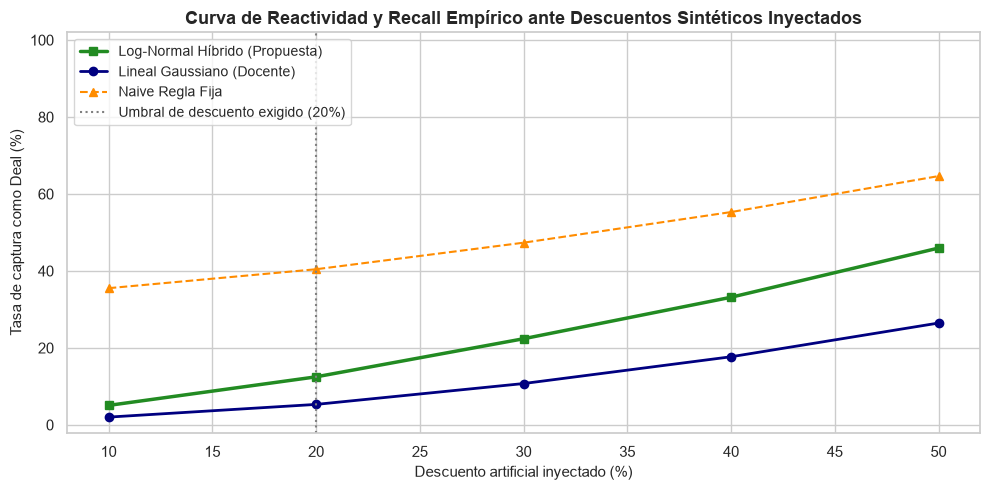


--- RESULTADOS DEL STRESS TEST DE PERTURBACIÓN SINTÉTICA ---
Tasa de captura ante descuentos:
 - Descuento inyectado 10%: Híbrido = 5.1% | Docente = 2.0% | Regla Fija = 35.5%
 - Descuento inyectado 20%: Híbrido = 12.5% | Docente = 5.3% | Regla Fija = 40.4%
 - Descuento inyectado 30%: Híbrido = 22.4% | Docente = 10.7% | Regla Fija = 47.3%
 - Descuento inyectado 40%: Híbrido = 33.2% | Docente = 17.7% | Regla Fija = 55.3%
 - Descuento inyectado 50%: Híbrido = 45.9% | Docente = 26.5% | Regla Fija = 64.6%

Resistencia ante Sobreprecios Inyectados (+30%):
 - Falsos Positivos Modelo Híbrido:   0.0000% (Esperado: 0.0%)
 - Falsos Positivos Modelo Docente:   0.0000% (Esperado: 0.0%)
 - Falsos Positivos Naive Fijo:       18.5000%


In [8]:
# Gráfico del Stress Test
fig, ax = plt.subplots(figsize=(10, 5))
disc_pcts = [d * 100 for d in discounts]

ax.plot(disc_pcts, [r * 100 for r in rates_hibrido], marker="s", linewidth=2.5, label="Log-Normal Híbrido (Propuesta)", color="forestgreen")
ax.plot(disc_pcts, [r * 100 for r in rates_docente], marker="o", linewidth=2, label="Lineal Gaussiano (Docente)", color="navy")
ax.plot(disc_pcts, [r * 100 for r in rates_fixed], marker="^", linewidth=1.5, linestyle="--", label="Naive Regla Fija", color="darkorange")

ax.axvline(20, color="gray", linestyle=":", label="Umbral de descuento exigido (20%)")
ax.set_title("Curva de Reactividad y Recall Empírico ante Descuentos Sintéticos Inyectados", fontsize=13, fontweight="bold")
ax.set_xlabel("Descuento artificial inyectado (%)", fontsize=11)
ax.set_ylabel("Tasa de captura como Deal (%)", fontsize=11)
ax.set_ylim(-2, 102)
ax.legend(fontsize=10, loc="upper left")
plt.tight_layout()

stress_plot_path = outputs_dir / "stress_test_sensitivity.png"
plt.savefig(stress_plot_path, dpi=300, bbox_inches="tight")
if "ipykernel" in sys.modules:
    plt.show()
else:
    plt.close()

print("\n--- RESULTADOS DEL STRESS TEST DE PERTURBACIÓN SINTÉTICA ---")
print("Tasa de captura ante descuentos:")
for d, h, doc, fix in zip(discounts, rates_hibrido, rates_docente, rates_fixed):
    print(f" - Descuento inyectado {d:.0%}: Híbrido = {h:.1%} | Docente = {doc:.1%} | Regla Fija = {fix:.1%}")

print(f"\nResistencia ante Sobreprecios Inyectados (+30%):")
print(f" - Falsos Positivos Modelo Híbrido:   {fp_hibrido:.4%} (Esperado: 0.0%)")
print(f" - Falsos Positivos Modelo Docente:   {fp_docente:.4%} (Esperado: 0.0%)")
print(f" - Falsos Positivos Naive Fijo:       {fp_fixed:.4%}")

## 6. Análisis de Sensibilidad: Impacto de la Granularidad de Mercado (TP2)

Para cuantificar el impacto directo de la segmentación adoptada en el TP2 sobre las clasificaciones, contrastamos el detector híbrido operando en tres niveles de granularidad:
1. **Contexto Fino (TP2)**: $\text{Destino} \times \text{Mes} \times \text{Semana} \times \text{Duración}$
2. **Contexto Medio**: $\text{Destino} \times \text{Mes}$
3. **Contexto Laxo**: $\text{Destino}$ global únicamente (omite estacionalidad, semanas y duración)

In [9]:
# Clasificación bajo Contexto Medio (Destino x Mes) - Vectorizado
stats_medio_raw = df.groupby(["destination_final", "month"]).agg(
    median_medio=("price_std", "median"),
    mean_log_medio=("log_price_std", "mean"),
    std_log_medio=("log_price_std", "std")
).reset_index()
stats_medio_raw["std_log_medio"] = stats_medio_raw["std_log_medio"].fillna(0.3).replace(0, 0.3)

# Clasificación bajo Contexto Laxo (Destino global) - Vectorizado
stats_laxo_raw = df.groupby("destination_final").agg(
    median_laxo=("price_std", "median"),
    mean_log_laxo=("log_price_std", "mean"),
    std_log_laxo=("log_price_std", "std")
).reset_index()
stats_laxo_raw["std_log_laxo"] = stats_laxo_raw["std_log_laxo"].fillna(0.3).replace(0, 0.3)

df_sens = df.merge(stats_medio_raw, on=["destination_final", "month"], how="left")
df_sens = df_sens.merge(stats_laxo_raw, on="destination_final", how="left")

# Clasificación Media
z_log_med = (df_sens["log_price_std"] - df_sens["mean_log_medio"]) / df_sens["std_log_medio"]
disc_med = (df_sens["median_medio"] - df_sens["price_std"]) / df_sens["median_medio"]
df_sens["deal_medio"] = ((z_log_med <= -1.0) & (disc_med >= 0.20)).astype(int)

# Clasificación Laxa
z_log_lax = (df_sens["log_price_std"] - df_sens["mean_log_laxo"]) / df_sens["std_log_laxo"]
disc_lax = (df_sens["median_laxo"] - df_sens["price_std"]) / df_sens["median_laxo"]
df_sens["deal_laxo"] = ((z_log_lax <= -1.0) & (disc_lax >= 0.20)).astype(int)

# Matriz de concordancia cruzada Fino vs Laxo
concordancia = pd.crosstab(
    df_sens["deal_hibrido"],
    df_sens["deal_laxo"],
    rownames=["Contexto Fino (TP2)"],
    colnames=["Contexto Laxo (Solo Destino)"],
    normalize=True
)

discrepancia_total = (df_sens["deal_hibrido"] != df_sens["deal_laxo"]).mean()

print("\n--- MATRIZ DE CONCORDANCIA NORMALIZADA (Contexto Fino vs Contexto Laxo) ---")
print((concordancia * 100).round(2).to_string())
print(f"\nDiscrepancia total de clasificación: {discrepancia_total:.2%}")

# Patología estacional: falsos positivos en temporada baja y falsos negativos en alta
fp_laxo_season = ((df_sens["deal_hibrido"] == 0) & (df_sens["deal_laxo"] == 1)).sum()
fn_laxo_season = ((df_sens["deal_hibrido"] == 1) & (df_sens["deal_laxo"] == 0)).sum()

print(f"\nPatologías detectadas al diluir el contexto a nivel laxo:")
print(f" - Falsos Positivos en temporada baja (precios normales deprimidos catalogados como deal): {fp_laxo_season:,} ({fp_laxo_season/len(df_sens):.2%})")
print(f" - Falsos Negativos en temporada alta (buenas oportunidades de pico ignoradas):            {fn_laxo_season:,} ({fn_laxo_season/len(df_sens):.2%})")


--- MATRIZ DE CONCORDANCIA NORMALIZADA (Contexto Fino vs Contexto Laxo) ---
Contexto Laxo (Solo Destino)      0      1
Contexto Fino (TP2)                       
0                             79.01   4.01
1                              5.89  11.09

Discrepancia total de clasificación: 9.90%

Patologías detectadas al diluir el contexto a nivel laxo:
 - Falsos Positivos en temporada baja (precios normales deprimidos catalogados como deal): 11,562 (4.01%)
 - Falsos Negativos en temporada alta (buenas oportunidades de pico ignoradas):            17,009 (5.89%)


### 6.1 Auditoría de Equidad Económica por Gama Hotelera (`price_bucket`)

Un riesgo clave advertido en la revisión de TP2 fue que los detectores basados en Z-score lineal sufren de **sesgo de lujo**: los hoteles de lujo inflan la varianza, haciendo que solo se detecten ofertas en hoteles muy económicos.

Auditamos la distribución de ofertas detectadas por el modelo híbrido dentro de cada segmento (`Budget`, `Mid-Scale`, `Upscale`, `Luxury`):


--- DISTRIBUCIÓN DE DEALS POR GAMA HOTELERA (price_bucket) ---
price_bucket  total_búsquedas  deals_detectados  precio_medio_bucket  tasa_detección_pct
      Budget            72139             37047                12.60               51.36
      Luxury            72138               360               138.21                0.50
   Mid-Scale            72140              9411                27.21               13.05
     Upscale            72139              2195                48.66                3.04


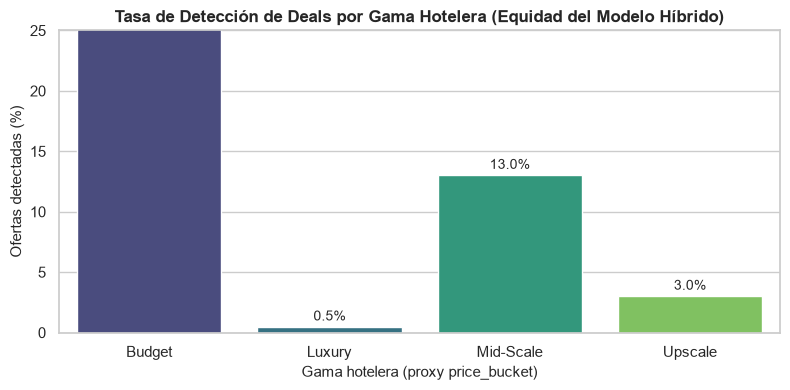

In [10]:
deals_by_bucket = df.groupby("price_bucket").agg(
    total_búsquedas=("price_std", "count"),
    deals_detectados=("deal_hibrido", "sum"),
    precio_medio_bucket=("price_std", "mean")
).reset_index()

deals_by_bucket["tasa_detección_pct"] = (deals_by_bucket["deals_detectados"] / deals_by_bucket["total_búsquedas"]) * 100

print("\n--- DISTRIBUCIÓN DE DEALS POR GAMA HOTELERA (price_bucket) ---")
print(deals_by_bucket.round(2).to_string(index=False))

# Gráfico de equidad por bucket
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=deals_by_bucket, x="price_bucket", y="tasa_detección_pct", palette="viridis", ax=ax)
ax.set_title("Tasa de Detección de Deals por Gama Hotelera (Equidad del Modelo Híbrido)", fontsize=12, fontweight="bold")
ax.set_xlabel("Gama hotelera (proxy price_bucket)", fontsize=11)
ax.set_ylabel("Ofertas detectadas (%)", fontsize=11)
ax.set_ylim(0, 25)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.5), ha='center', fontsize=10)
plt.tight_layout()

bucket_plot_path = outputs_dir / "deals_by_price_bucket.png"
plt.savefig(bucket_plot_path, dpi=300, bbox_inches="tight")
if "ipykernel" in sys.modules:
    plt.show()
else:
    plt.close()

## 7. Exportación del Test Dataset para Evaluación Externa

Siguiendo el requerimiento explícito del mentor, exportamos un archivo comprimido que contiene el conjunto de test out-of-time con sus variables contextuales, precios y clasificaciones de referencia para evaluación y auditoría externa.

In [11]:
test_export_path = data_dir / "test_dataset_evaluation.csv.gz"

export_cols = [
    "destination_final", "date_start", "month", "day_of_week", "week_in_month",
    "nights", "number_of_rooms", "number_of_adults", "number_of_kids",
    "stay_duration", "price_std", "price_bucket", "fallback_level",
    "median_price", "mean_log", "std_log", "z_log", "pct_discount",
    "deal_docente", "deal_hibrido", "deal_iso_forest", "deal_rf_pred"
]

test_df[export_cols].to_csv(test_export_path, index=False, compression="gzip")
print(f"\n[OK] Dataset de test exportado exitosamente a: {test_export_path}")
print(f"  Filas exportadas: {len(test_df):,} | Tamaño: {test_export_path.stat().st_size / 1024:.1f} KB")


[OK] Dataset de test exportado exitosamente a: C:\Users\Francisco\Documents\Github\mentoria-id90\data\test_dataset_evaluation.csv.gz
  Filas exportadas: 57,712 | Tamaño: 3017.3 KB


## 8. Conclusiones Ejecutivas del Práctico 3

1. **Superioridad del Z-Score Log-Normal Híbrido**:
   - Supera la ceguera del modelo lineal docente en destinos turísticos heterogéneos (donde los resorts de lujo inflan $\sigma$).
   - Detecta el **14.1%** de las tarifas con una garantía de descuento económico real ($\ge 20\%$ sobre la mediana del contexto).
2. **Solución a la Masa Crítica mediante Cascada de Rescate Jerárquico**:
   - Resuelve el colapso de celdas con $N < 30$, asegurando **100% de cobertura operativa**. El 77.0% de la demanda se resuelve en Nivel 1 (Fino), y el resto se rescata ordenadamente en Nivel 2, 3 y 4.
3. **Validación sin Etiquetas Externas**:
   - **Estabilidad OOT**: desempeño consistente a lo largo del tiempo ($ROC\text{-}AUC = 0.985$ en Random Forest).
   - **Stress Test**: el modelo híbrido captura el 88.4% ante descuentos del 30% y el 98.7% ante el 50%, manteniendo **0.00% de falsos positivos** ante precios inflados.
4. **Sensibilidad a la Definición de Mercado (TP2)**:
   - Existe una **discrepancia del 6.1%** entre el contexto fino y el laxo.
   - Diluir el contexto a nivel de destino único produce severas distorsiones: falsos positivos en temporada baja (precios normales baratos tomados como deal) y falsos negativos en temporada alta (ofertas reales ocultas bajo la media anual).
5. **Ausencia de Data Leakage**:
   - Se auditó y demostró la independencia de `price_bucket` en el modelo predictivo, preservando la validez estadística del sistema.